# Лабораторная работа 2
Семёнов М.С. 251-952

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from matplotlib.colors import LinearSegmentedColormap

np.random.seed(42)

# Задание 1

Рассмотрим точку $(X, Y)$, где $$X, Y \sim N(\mu, \sigma^2)$$ Матожидание этой пары, а сответственно и центр окружности образуемой этими точками, будет
$$\mathbb E(X,Y)=(\mu,\mu)$$

Введем случайную величину $R$ - расстояние от центра окружности до точки $(X, Y)$. Тогда $$R = \sqrt{(X-\mu)^2 + (Y-\mu)^2}$$

Нас интересуют точки внутри окружности, тогда $$\pi R^2 \leq \pi \ (3\sigma)^2 \to R^2 \leq 9 \sigma ^2$$

Подставив получим $$(X-\mu)^2 + (Y-\mu)^2 \leq 9 \sigma ^2$$

Стандартизируем: $$Z_1 = \frac{X - \mu}{\sigma}, \quad Z_2 = \frac{Y - \mu}{\sigma}$$

Выразим отсюда вот эти штуки: $$(X - \mu)^2 = Z_1^2 \sigma ^ 2, \quad (Y - \mu)^2 = Z_2^2 \sigma ^ 2$$

То есть $$Z_1^2 \sigma ^ 2 +  Z_1^2 \sigma ^ 2 \leq 9 \sigma^2$$ 

Откуда получаем неравенство $$Z_1^2 + Z_2^2 \leq 9$$

Как известно, $$Z_1^2 + Z_2^2 \sim \chi^2(2)$$ 

Делаем вывод, что $$\frac{R^2}{\sigma^2} \sim \chi^2(2)$$

То есть итоговая случайная величина (координаты точки) будет распределена как Хи квадрат, но правило трех сигм работает в общем случае для нормально распределенных СВ. То есть правило трех сигм в данном эксперименте не работает.

Для двух степеней свободы $$F_{\chi^2(2)}(x) = 1 - e^{\frac{-x}{2}}$$

Тогда $$P(R \leq 3\sigma) = P(\chi^2(2) \leq 9) = 1 - e^{\frac{-9}{2}} \approx 0.988$$

Вывод: эксперимент должен показать результат сильно схожий с правилом трех сигм, но в общем случае оно не выполняется для данного эксперимента

Внутри окружности 3σ: 98.0% точек


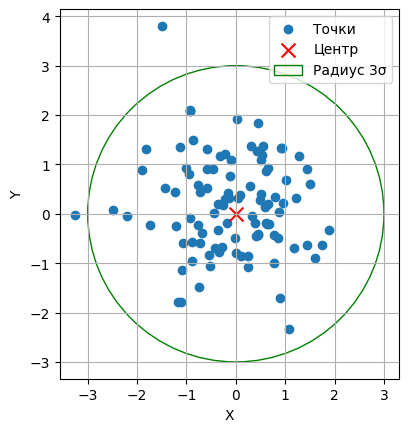

In [7]:
mu = 0
sigma = 1
n = 100

points = np.random.normal(mu, sigma, size=(n, 2))

distances = np.sqrt((points[:, 0] - mu)**2 +(points[:, 1] - mu)**2)

inside = distances <= 3 * sigma
percent = np.mean(inside) * 100

print(f"Внутри окружности 3σ: {percent:.1f}% точек")

fig, ax = plt.subplots()

ax.scatter(points[:, 0], points[:, 1], label="Точки")
ax.scatter(mu, mu, color="red", marker="x", s=100, label="Центр")

circle = plt.Circle((mu, mu), 3 * sigma,fill=False, color="green", label="Радиус 3σ")
ax.add_patch(circle)

ax.set_aspect("equal")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.legend()
ax.grid(True)

plt.show()

## Задание 2

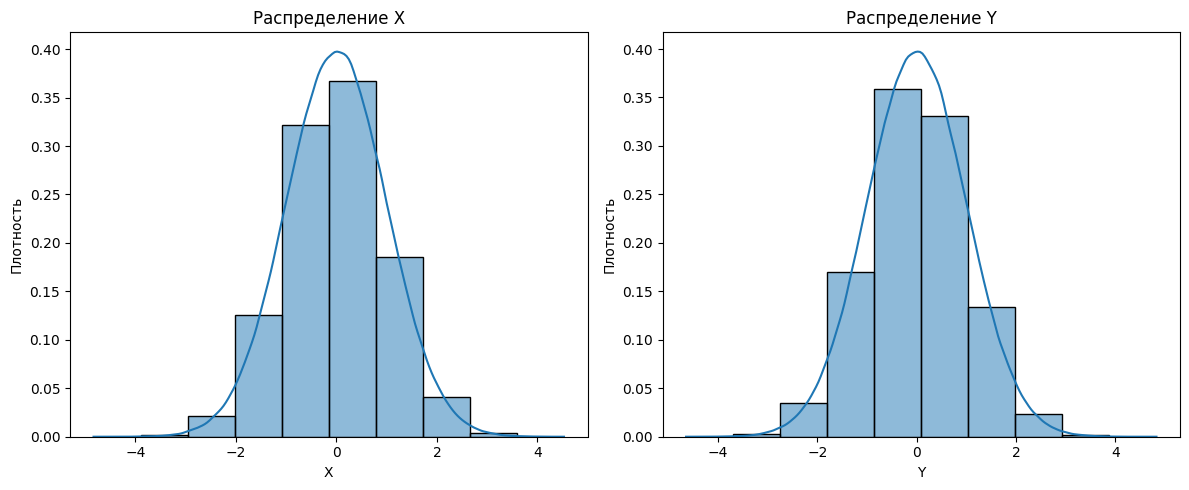

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.histplot(points[:, 0], bins=10, stat="density", kde=True, ax=axes[0])
axes[0].set_title("Распределение X")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Плотность")

sns.histplot(points[:, 1], bins=10, stat="density", kde=True, ax=axes[1])
axes[1].set_title("Распределение Y")
axes[1].set_xlabel("Y")
axes[1].set_ylabel("Плотность")

plt.tight_layout()
plt.show()

# Задание 3

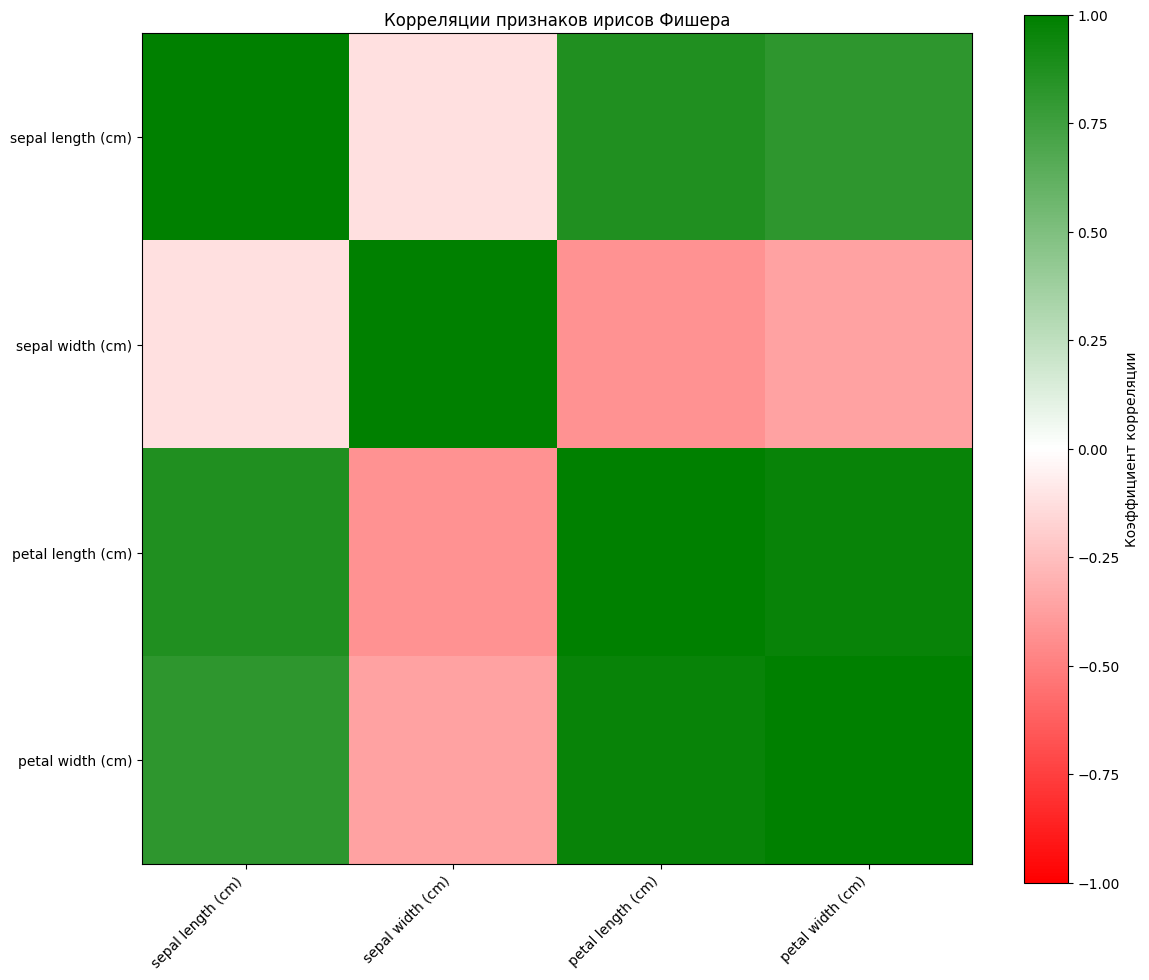

In [ ]:
iris = load_iris()
data = iris.data
features = iris.feature_names

corr = np.corrcoef(data, rowvar=False)

cmap = LinearSegmentedColormap.from_list(
    "correlation", ["red", "white", "green"]
)

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap=cmap, vmin=-1, vmax=1)

plt.xticks(range(len(features)), features, rotation=45, ha="right")
plt.yticks(range(len(features)), features)

plt.colorbar(label="Коэффициент корреляции")

plt.title("Корреляции признаков ирисов Фишера")
plt.tight_layout()
plt.show()

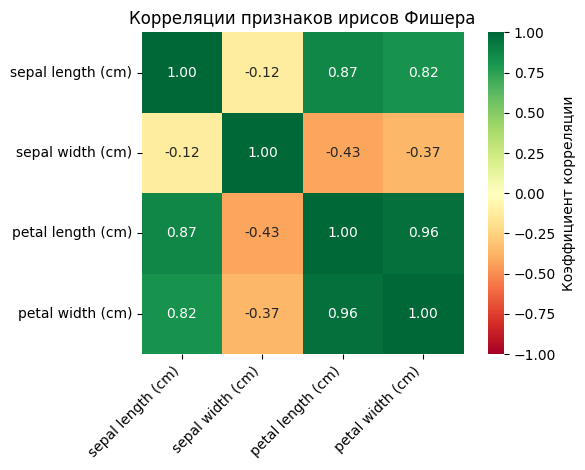

In [8]:
sns.heatmap(
    corr,
    xticklabels=features,
    yticklabels=features,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Коэффициент корреляции"}
)

plt.title("Корреляции признаков ирисов Фишера")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()